# Clase 1 EDA

El Análisis Exploratorio de Datos (EDA) es el proceso de explorar y analizar datos para encontrar patrones, tendencias y relaciones, identificando valores atípicos (outliers) y errores que puedan afectar los resultados.

### Objetivos y Pasos del EDA
* **Objetivos:** Contestar preguntas de negocio, plantear nuevas hipótesis y tomar decisiones basadas en datos.
* **Pasos:**
  1. Transformar los datos (manejo de nulos y atípicos).
  2. Visualizar.
  3. Analizar e Interpretar.
  4. Documentar.

### Tipos de Variables
* **Categóricas:** Nominales (sin jerarquía, ej. estado civil) u Ordinales (con progresión, ej. medallas de oro/plata/bronce).
* **Numéricas:** Discretas (conteos enteros, ej. número de hijos) o Continuas (valores infinitos en un rango, ej. estatura).

### Repaso de Estadística Básica
* **Rango:** Diferencia entre el valor máximo y mínimo.
* **Rango Intercuartílico:** ``IQR = Q3 - Q1'' donde ``IQR'' es el rango intercuartílico que mide la dispersión estadística, ``Q3'' es el tercer cuartil (o percentil 75) y ``Q1'' es el primer cuartil (o percentil 25).
* **Asimetría (Sesgo):** Puede ser positiva (mayor dispersión a la derecha), negativa (a la izquierda) o simétrica.
* **Curtosis:** Mide la concentración de datos (Leptocúrtica > 0, Mesocúrtica = 0, Platicúrtica < 0).

In [1]:
#Importar las herramientas principales para el EDA- Centrando sólo en temario en extra en el CV habrá más
#Limpieza y clasificación
import pandas as pd
import numpy as np
#Visualización- Hay muchos más
import matplotlib.pyplot as plt
import seaborn as sns

#Cargar el dataset pinguin- Este es uno de ejemplo que ya está cargado en Google Colab
df=sns.load_dataset('penguins')




In [2]:
#1. Quiero identificar los tipos de datos (categóricos o numéricos) y ver los no nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


En un primer vistazo podemos ver que especies, islas y sexo son categóricos (objetos) y por otro lado, longitud, profundidad, longitud de la aleta y la masa son numéricos. De aquí me puede interesar quedarme con la longitud de la aleta, la especie, la isla y la profundidad de la isla. ¿Para qué? Para ver si la longitud de la aleta está relacionada con la especie o la isla que habita.

In [3]:
#Análisis descriptivo- Media, desviación estándar, minimos, maximos y quartiles
display(df.describe())

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


describe lo vamos a utilizar para hacer una pequeña extracción de los datos numéricos y para hacer un footprinting para ver si hay un patrón.

# Quitar los nulos

1. ¿Es importante el valor? Es decir si quito ese valor no se va a ver afectado el dataset.
2. ¿Si lo retiro hay sesgo? Porque al quitar se pueden producir sesgos.

Para evitarlo nombrar dataframes intermedios, es un dataframe con la información quitada con un nombre distinto al original.

In [4]:
print(df.isnull().sum())#¿Cuántos nulos hay en mi dataset? Y después me los muestras con el print

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


In [6]:
df_null=df.dropna()#Quitame todos los NaN y guardamelos en df_null
display(df_null)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,Female
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


# Poner 0s

In [13]:
df_ceros=df.fillna(0)
display(df_ceros)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,0.0,0.0,0.0,0.0,0
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,0.0,0.0,0.0,0.0,0
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


# Cambiarlo por la media

In [15]:
df_media = df.fillna(df.mean(numeric_only=True))
display(df_media)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.10000,18.70000,181.000000,3750.000000,Male
1,Adelie,Torgersen,39.50000,17.40000,186.000000,3800.000000,Female
2,Adelie,Torgersen,40.30000,18.00000,195.000000,3250.000000,Female
3,Adelie,Torgersen,43.92193,17.15117,200.915205,4201.754386,NaN
4,Adelie,Torgersen,36.70000,19.30000,193.000000,3450.000000,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,43.92193,17.15117,200.915205,4201.754386,NaN
340,Gentoo,Biscoe,46.80000,14.30000,215.000000,4850.000000,Female
341,Gentoo,Biscoe,50.40000,15.70000,222.000000,5750.000000,Male
342,Gentoo,Biscoe,45.20000,14.80000,212.000000,5200.000000,Female


# Representación de datos



*   Variables categóricas: tabla de frecuencias, histograma de conteo y gráficos circulares (pie).
*   Variables numéricas: Gráficos de línea/dispersión, histogramas y gráficos de densidad.



In [7]:
#1. Análisis de variables categóricas

tabla_frecuencias=df['species'].value_counts()
display(tabla_frecuencias)

,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


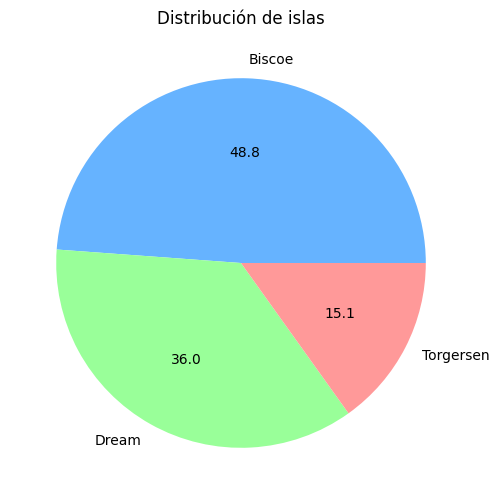

In [8]:
# Gráfico circular para la isla de procedencia
plt.figure(figsize=(6,6))
df['island'].value_counts().plot.pie(autopct='%1.1f',colors=['#66b3ff','#99ff99','#ff9999'])
plt.title('Distribución de islas')#Titulo importante
plt.ylabel('')#Quitar el eye y porque no aporta
plt.show()

Como podemos ver en el gráfico circular hay una mayor distribución de pinguinos en la isla Biscoe respecto a las otras dos.

/tmp/ipykernel_5730/3603675170.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,x='species', palette='viridis')


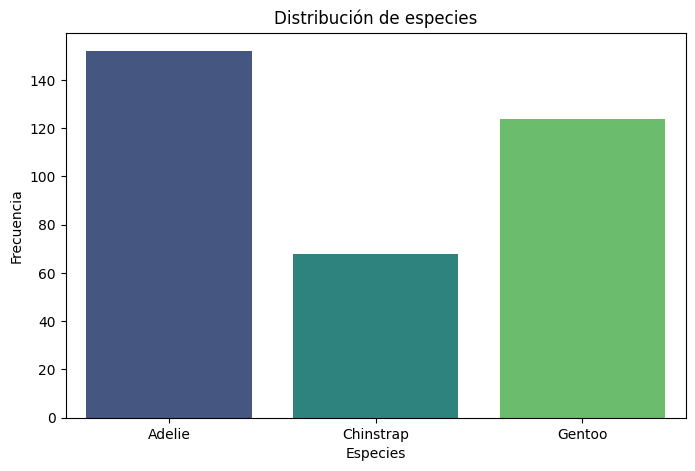

In [9]:
#Histograma
plt.figure(figsize=(8,5))
sns.countplot(data=df,x='species', palette='viridis')
plt.title('Distribución de especies')
plt.xlabel('Especies')
plt.ylabel('Frecuencia')
plt.show()

# Análisis de variables numéricas
1. La longitud de las aletas.
2. Su valor medio.

Text(0, 0.5, 'Frecuencia')

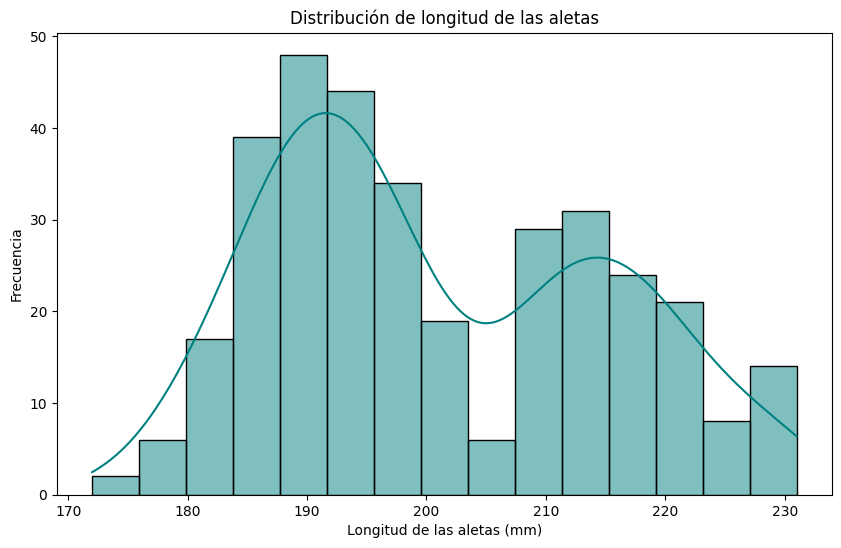

In [10]:
plt.figure(figsize=(10,6))
sns.histplot(data=df,x='flipper_length_mm', kde=True,bins=15,color='teal')
plt.title('Distribución de longitud de las aletas')
plt.xlabel('Longitud de las aletas (mm)')
plt.ylabel('Frecuencia')

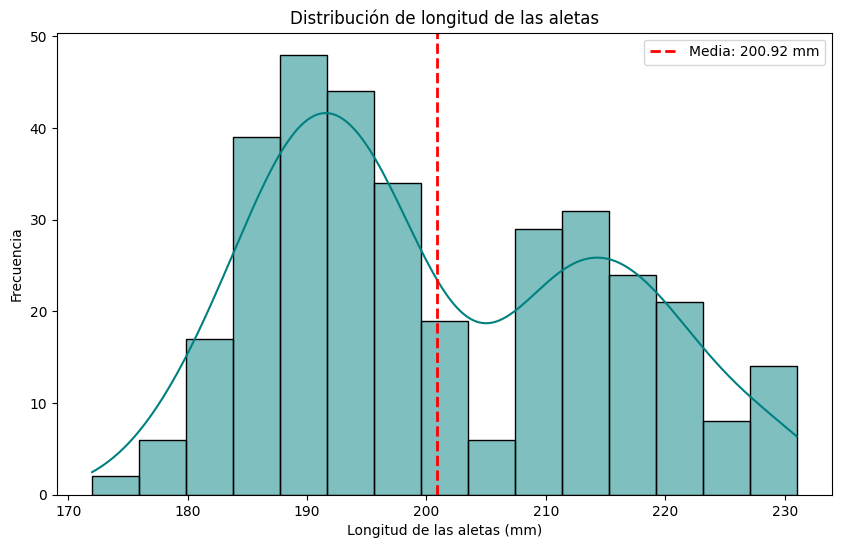

In [12]:
#Agregar una línea vertical para ver la media
plt.figure(figsize=(10,6))
sns.histplot(data=df,x='flipper_length_mm', kde=True,bins=15,color='teal')
plt.title('Distribución de longitud de las aletas')
plt.xlabel('Longitud de las aletas (mm)')
plt.ylabel('Frecuencia')


media_aletas=df['flipper_length_mm'].mean()
plt.axvline(media_aletas,color='red',linestyle='dashed',linewidth=2,label=f'Media: {media_aletas:.2f} mm')
plt.legend()
plt.show()